# 8장. 작은 데이터 분석 프로젝트 완성하기

이 노트북은 **질문 → 원본 데이터 점검 → 전처리 → PK/FK 검증 → 안전한 병합 → completed 범위 집계 → 총합 대조 → 시각화 → 보고서 → 최종 Validation**을 하나의 재현 가능한 프로젝트로 연결합니다.

> 코드가 끝까지 실행되었다는 사실만으로 프로젝트가 검증된 것은 아닙니다. 같은 의미의 숫자와 공개 산출물이 정해 둔 기준을 함께 통과해야 합니다.


## 제출 정보
- 이름: 김지인
- GitHub ID: jiin-0
- 작성일: 2026-11-04
- 최종 Notebook URL: https://github.com/jiin-0/llm-data-analysis-study/blob/main/chapter08/ch08_midterm_project.ipynb

## 학습 목표

- 원본 데이터를 보존하며 전처리합니다.
- 주요 PK의 결측·중복과 FK 미매칭을 확인합니다.
- `validate`와 `indicator` 관점으로 병합 결과를 검증합니다.
- `line_total = quantity × unit_price`를 다시 확인합니다.
- 금액성 분석은 `order_status == "completed"` 범위를 사용합니다.
- 카테고리·월·고객 금액 합계를 같은 source total과 대조합니다.
- 날짜 오류로 월별 금액이 누락되지 않는지 확인합니다.
- 공개 고객 결과에서 원본 고객 ID와 직접 식별정보를 제거합니다.
- 결과 CSV, 그래프, Markdown 보고서와 PASS/FAIL Evidence를 저장합니다.
- 전체 파이프라인을 다시 실행해 재현성을 확인합니다.


## 1. 프로젝트 루트와 출력 폴더 설정

VS Code에서 현재 작업 폴더가 프로젝트 루트 또는 `notebooks`일 수 있으므로 상위 폴더를 탐색합니다.


In [4]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"

for path in [PROCESSED_DIR, REPORT_DIR, FIGURE_DIR]:
    path.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Python 실행 파일:", sys.executable)
print("프로젝트 루트:", PROJECT_ROOT)
print("원본 데이터 폴더:", RAW_DIR)
print("보고서 폴더:", REPORT_DIR)


Python 실행 파일: c:\dev\llm-data-analysis-study\.venv\Scripts\python.exe
프로젝트 루트: C:\dev\llm-data-analysis-study
원본 데이터 폴더: C:\dev\llm-data-analysis-study\data\raw
보고서 폴더: C:\dev\llm-data-analysis-study\reports


## 2. 프로젝트 함수 불러오기

Notebook과 일괄 실행 스크립트가 같은 `src.midterm_project` 함수를 사용하도록 하여 계산 기준이 어긋나는 문제를 줄입니다.


In [5]:
from src.data_loader import load_sales_data
from src.preprocessing import (
    compare_shapes,
    preprocess_sales_data,
    save_processed_data,
    validate_relationships,
)
from src.midterm_project import (
    FORBIDDEN_CUSTOMER_COLUMNS,
    build_analysis_tables,
    build_interpretation_notes,
    build_key_duplicate_checks,
    build_midterm_report,
    build_project_validation,
    create_project_figures,
    run_midterm_project,
    save_project_tables,
    summarize_datasets,
)


## 3. 원본 데이터 확인

프로젝트는 `data/raw`의 원본 4개 파일에서 시작합니다. 파일이 없다면 프로젝트 루트에서 `python scripts/generate_sample_data.py`를 먼저 실행합니다.


In [6]:
raw_data = load_sales_data(RAW_DIR)

dataset_summary = summarize_datasets(raw_data)
display(dataset_summary)

for name, df in raw_data.items():
    print(f"\n===== {name} =====")
    print("shape:", df.shape)
    print("columns:", df.columns.tolist())
    print("missing values:", int(df.isna().sum().sum()))
    print("duplicated rows:", int(df.duplicated().sum()))


,dataset,rows,columns,missing_values,duplicated_rows
0,customers,150,6,0,0
1,products,100,4,0,0
2,orders,300,5,0,0
3,order_items,764,5,0,0



===== customers =====
shape: (150, 6)
columns: ['customer_id', 'name', 'gender', 'age', 'city', 'signup_date']
missing values: 0
duplicated rows: 0

===== products =====
shape: (100, 4)
columns: ['product_id', 'product_name', 'category', 'price']
missing values: 0
duplicated rows: 0

===== orders =====
shape: (300, 5)
columns: ['order_id', 'customer_id', 'order_date', 'payment_method', 'order_status']
missing values: 0
duplicated rows: 0

===== order_items =====
shape: (764, 5)
columns: ['order_item_id', 'order_id', 'product_id', 'quantity', 'unit_price']
missing values: 0
duplicated rows: 0


## 1. 프로젝트 질문
### 분석 질문
 어떤 계절에 가장 많은 매출이 발생할까? 

### 분석 범위
1년(12개월), 주문 완료 금액

### 사용할 데이터와 지표
orders-order_date/orders-order_status/order_items-quantity/order_items-unit_price
키: order_id

### 계산 기준
- `order_status == "completed"` 적용 여부: O
- `line_total = quantity × unit_price` 확인 여부: O

### 완료 기준
1. order_id key로 orders와 order_items 파일 연결
2. order_stats==completed인 주문만 filtering 되어야함
3. 각 주문일자에 맞춰 month column 생성
4. 계절(입춘/입하/입추/입동 날 기반으로 계절 구분)에 맞춰 주문 금액 합산 표 제작
5. 금액 차이를 볼 수 있는 시각화 자료 제작

## 4. 원본을 보존하며 전처리

`preprocess_sales_data()`는 원본 DataFrame을 직접 수정하지 않고 전처리된 복사본을 반환합니다. 전처리 전후 행 수가 달라졌다면 그 이유를 설명할 수 있어야 합니다.


In [7]:
processed_data = preprocess_sales_data(raw_data)
processed_paths = save_processed_data(processed_data, PROCESSED_DIR)

preprocessing_comparison = compare_shapes(raw_data, processed_data)
display(preprocessing_comparison)

for path in processed_paths:
    print(path, "OK" if path.exists() else "MISSING")


,dataset,rows_raw,columns_raw,rows_processed,columns_processed
0,customers,150,6,150,6
1,order_items,764,5,764,6
2,orders,300,5,300,7
3,products,100,4,100,4


C:\dev\llm-data-analysis-study\data\processed\customers_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\products_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\orders_clean.csv OK
C:\dev\llm-data-analysis-study\data\processed\order_items_clean.csv OK


In [6]:
customers = pd.read_csv(PROCESSED_DIR / 'customers_clean.csv')
products = pd.read_csv(PROCESSED_DIR / 'products_clean.csv')
orders = pd.read_csv(PROCESSED_DIR / 'orders_clean.csv')
order_items = pd.read_csv(PROCESSED_DIR / 'order_items_clean.csv')

In [7]:
order_items.columns
orders.columns

Index(['order_id', 'customer_id', 'order_date', 'payment_method',
       'order_status', 'order_month', 'order_dayofweek'],
      dtype='str')

## 2. 입력 데이터와 전처리 검증
- 사용 원본 파일: customers/order_items/orders/products
- shape: (150,6)/(764,5)/(300,5)/(100,4)
- 핵심 결측/중복 결과: X
- 전처리 전후 변화: O

![입력 데이터 검증](images/step02_data_validation.png)

### 나의 해석과 판단
전처리 후 order_itmes, orders의 column이 증가하였다.
order_items는 line_total값을 추가하여 column 수가 증가하였고, orders는 order_month, order_dayofweek column을 추가하였다. 날짜에 기반을 둔 분석을 진행할 예정이므로, orders에 날짜를 월별로 분리가능하도록 column을 추가하는 것이 필요했다. 또한, 주문 완료 총액을 기준하기 때문에 각 총액을 미리 계산해둘 필요가 있었다.

### 한계와 추가 확인 사항
새로운 column들에 입력된 값이 올바른 값인지 확인이 필요하다.


## 5. PK와 FK를 먼저 검증

전체 행 중복과 PK 중복은 다릅니다. 고객·상품·주문·주문 상세의 PK는 **결측 0, 중복 0**이어야 합니다. FK는 부모 테이블에 없는 참조 ID가 0건이어야 합니다.


In [8]:
key_duplicate_checks = build_key_duplicate_checks(processed_data)
relationship_checks = validate_relationships(processed_data).copy()

if not relationship_checks.empty:
    relationship_checks["status"] = (
        relationship_checks["invalid_count"]
        .eq(0)
        .map({True: "PASS", False: "FAIL"})
    )

display(key_duplicate_checks)
display(relationship_checks)

assert key_duplicate_checks["status"].eq("PASS").all(), "PK Validation 실패"
assert (
    not relationship_checks.empty
    and relationship_checks["invalid_count"].eq(0).all()
), "FK Validation 실패"

print("PK/FK Gate: PASS")


,dataset,key,missing_count,duplicate_count,status,detail
0,customers,customer_id,0,0,PASS,
1,products,product_id,0,0,PASS,
2,orders,order_id,0,0,PASS,
3,order_items,order_item_id,0,0,PASS,


,check,invalid_count,status
0,orders.customer_id exists in customers.custome...,0,PASS
1,order_items.order_id exists in orders.order_id,0,PASS
2,order_items.product_id exists in products.prod...,0,PASS


PK/FK Gate: PASS


## 6. 안전한 병합과 계산 관계 검증

`build_analysis_tables()`는 다음을 한 번에 준비합니다.

- 주문 상세 → 주문: `many_to_one`
- 주문 상세 → 상품: `many_to_one`
- 고객 집계 → 고객: `one_to_one`
- 병합 전후 행 수와 미매칭 확인
- `line_total = quantity × unit_price` 확인
- completed 주문 범위 확정
- 날짜 오류 확인


In [9]:
analysis_tables = build_analysis_tables(processed_data)

display(analysis_tables["merge_checks"])
display(analysis_tables["line_total_check"])
display(analysis_tables["date_checks"])
display(analysis_tables["amount_scope_summary"])

assert analysis_tables["merge_checks"]["status"].eq("PASS").all()
assert analysis_tables["line_total_check"]["status"].eq("PASS").all()

print("병합 / line_total Gate: PASS")


,merge,validate,before_rows,after_rows,row_count_preserved,unmatched_count,status
0,order_id → orders,many_to_one,764,764,True,0,PASS
1,product_id → products,many_to_one,474,474,True,0,PASS
2,customer_id → customers,one_to_one,100,100,True,0,PASS


,check,source,row_count,mismatch_count,status
0,line_total = quantity × unit_price,existing,764,0,PASS


,check,invalid_count,affected_amount,status
0,completed rows with invalid order_date,0,0.0,PASS


,scope,amount,detail_rows
0,all_order_items,255610000.0,764
1,completed_order_items,148990000.0,474
2,excluded_non_completed,106620000.0,290


병합 / line_total Gate: PASS


## 3. PK/FK·병합 검증
### PK 결과
- 결측: 0
- 중복: 0
- PASS/FAIL: PASS

### FK 결과
- 미매칭: X
- PASS/FAIL: PASS

### 병합 결과
- validate 관계: many_to_one(order_id->orders/product_id->products), one_to_one(customer_id->customers)
- 병합 전 행 수: 764/474/100
- 병합 후 행 수: 764/474/100
- 미매칭: X
- PASS/FAIL: PASS

### 나의 해석과 판단
키 누락이나 미매치가 존재하지 않았다.

## 7. 핵심 분석 결과 확인

세 금액성 결과는 같은 `completed_order_sales`에서 출발합니다. 주문 상태 분포만 전체 주문을 사용합니다.


In [10]:
category_sales = analysis_tables["category_sales"]
monthly_sales = analysis_tables["monthly_sales"]
customer_sales_internal = analysis_tables["customer_sales"]
customer_sales_public = analysis_tables["customer_sales_public"]
order_status_summary = analysis_tables["order_status_summary"]

display(category_sales)
display(monthly_sales)
display(customer_sales_public.head(10))
display(order_status_summary)

print("내부 고객 결과 컬럼:", customer_sales_internal.columns.tolist())
print("공개 고객 결과 컬럼:", customer_sales_public.columns.tolist())


,category,total_quantity,total_sales,sales_ratio
0,스포츠,295,31743000,21.31
1,전자기기,259,26400000,17.72
2,생활용품,272,23915000,16.05
3,뷰티,223,23383000,15.69
4,식품,133,16573000,11.12
5,도서,149,16389000,11.00
6,패션,111,10587000,7.11


,order_month,total_sales,order_count,avg_order_value
0,2025-10,2650000,5,530000.0
1,2025-11,16970000,19,893158.0
2,2025-12,11021000,13,847769.0
3,2026-01,24278000,25,971120.0
4,2026-02,11079000,14,791357.0
5,2026-03,6578000,9,730889.0
6,2026-04,16529000,23,718652.0
7,2026-05,12228000,19,643579.0
8,2026-06,15949000,16,996812.0
9,2026-07,14482000,19,762211.0


,customer_label,city,order_count,total_sales,avg_order_value
0,Customer 01,성남,5,4100000,820000.0
1,Customer 02,고양,4,3996000,999000.0
2,Customer 03,수원,4,3880000,970000.0
3,Customer 04,서울,5,3590000,718000.0
4,Customer 05,서울,4,3523000,880750.0
5,Customer 06,인천,2,3191000,1595500.0
6,Customer 07,성남,2,3178000,1589000.0
7,Customer 08,광주,3,3153000,1051000.0
8,Customer 09,서울,4,3093000,773250.0
9,Customer 10,부산,2,2990000,1495000.0


,order_status,order_count,order_ratio
0,completed,184,61.33
1,cancelled,64,21.33
2,refunded,52,17.33


내부 고객 결과 컬럼: ['customer_id', 'customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
공개 고객 결과 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']


## 8. 같은 의미의 금액 총합을 교차 검증

같은 completed 범위에서 만든 결과라면 다음 네 금액이 일치해야 합니다.

```text
completed source total
= category total
= monthly total
= customer total
```

날짜 오류가 있으면 월별 합계가 source total보다 작아질 수 있으므로 별도 Gate로 확인합니다.


In [11]:
total_consistency = analysis_tables["total_consistency_check"]
display(total_consistency)

assert total_consistency["matches_completed"].all(), "Total consistency Gate 실패"
assert analysis_tables["date_checks"]["status"].eq("PASS").all(), "날짜 Gate 실패"

print("Total consistency / Date Gate: PASS")


,source,amount,difference_from_completed,matches_completed,status
0,completed_source,148990000.0,0.0,True,PASS
1,category,148990000.0,0.0,True,PASS
2,monthly,148990000.0,0.0,True,PASS
3,customer,148990000.0,0.0,True,PASS


Total consistency / Date Gate: PASS


## 9. 공개 고객 결과의 개인정보를 확인

내부 계산에는 `customer_id`가 필요할 수 있지만 공개 CSV·그래프·보고서에는 원본 고객 ID와 직접 식별정보를 포함하지 않습니다. 공개 라벨은 `Customer 01` 같은 순위 기반 라벨을 사용합니다.


In [12]:
forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(customer_sales_public.columns)
)
print("공개 결과 금지 컬럼:", forbidden)

assert not forbidden, "Privacy Gate 실패"
assert "customer_id" not in customer_sales_public.columns
print("Privacy Gate: PASS")


공개 결과 금지 컬럼: []
Privacy Gate: PASS


## 10. 최종 PASS/FAIL Validation

지금까지의 핵심 Gate를 하나의 표로 정리합니다. 하나라도 FAIL이면 결과를 제출 가능한 완료 상태로 보지 않습니다.


In [13]:
project_validation = build_project_validation(
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
)
display(project_validation)

assert project_validation["status"].eq("PASS").all(), "최종 Validation 실패"
print("Project Validation: PASS")


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


Project Validation: PASS


## 4. 핵심 EDA 결과
### 결과 1
- 수치/표: 카테고리별 판매량 표
- 결과 관찰: 스포츠가 매출액의 21.31%를 차지함. 패션은 7.11%로 가장 낮음. 판매량이 가장 많은 카테고리는 스포츠(295개)이며, 패션이 111개로 판매량이 가장 적음.
- 나의 해석과 판단: 
- 업무·분석적 의미: 주문 완료금액 분석을 통해 쇼핑몰에서 많이 팔리는 카테고리를 분석할 수 있다. 또한 금액과 판매수를 함께 분석하여 평균 단가 분석이 가능하다.
- 한계: 완료 주문금액이긴하나 쿠폰적용이나 할인이 반영되어 있지 않아 실제 순이익을 알 수 없다.

### 결과 2
- 수치/표: 월별 매출액 표
- 결과 관찰: 월 매출액은 2026년 1월에 가장 높았고, 2025년 10월이 가장 낮았다. 또한, 2026년 1월이 25건으로 가장 많았다.
- 나의 해석과 판단: 2026년 1월의 매출액이 가장 높았던 것은 주문 수가 많았던 점과 관련 있을 수 있다. 평균 주문 금액은 2026년 10월이 가장 높았으며, 이때는 주문 건수가 3건이어 섣불리 판단할 수 없다.
- 업무·분석적 의미: 월별 매출과 주문수를 함께 확인하여 매출 변화와 주문수 사이 관계를 살펴볼 수 있다.
- 한계: 마지막 달과 첫 달의 경우 날짜가 월 전체를 포함하지 않을 수 있다.

### 결과 3
- 수치/표: 고객별 상위 10명 매출 표
- 결과 관찰: 고객별 매출은 customer 01이 가장 높았다.
- 나의 해석과 판단: 고객별 매출 상위 고객을 확인할 수 있었다. 그러나 단순히 주문 수와 매출만으로 고객의 지속성이나 충성도를 판단하기는 어려우므로 구매 주기를 확인해볼 필요가 있다.
- 업무·분석적 의미: 상위 고객의 구매 특성을 분석할 필요가 있다. 기간 내로 몰아서 구매하는지 꾸준하게 구매하는지 확인이 필요하다.
- 한계: 상위 10명의 고객을 선별하였기 때문에 전체 고객을 대표하지 않을 수 있다.

## 5. Total consistency와 날짜 검증
- completed source total:148990000.0
- category total:148990000.0
- monthly total:148990000.0
- customer total:148990000.0
- 총합 일치 여부:O
- completed 주문 날짜 오류 건수:O
- 날짜 오류 영향 금액: O(날짜 오류 X)

### 불일치가 있었다면 원인
X

## 11. 해석 메모와 결과 CSV 저장

관찰, 주의점, 다음 질문을 분리합니다. 저장되는 `ch08_customer_sales.csv`는 공개용 컬럼만 포함합니다.


In [14]:
interpretation_notes = build_interpretation_notes()
display(interpretation_notes)

saved_tables = save_project_tables(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
    REPORT_DIR,
)

for path in saved_tables:
    print(path.name, path.exists(), path.stat().st_size)


,analysis,observation,caution,next_question
0,카테고리별 completed 주문 기준 금액,completed 주문 기준 금액 비중이 높은 카테고리를 확인할 수 있습니다.,금액이 높은 이유가 판매 수량인지 단가인지 구분해야 합니다.,카테고리별 평균 판매 단가는 어떻게 다른가?
1,월별 completed 주문 기준 금액,시간에 따른 completed 주문 기준 금액의 증가와 감소를 확인할 수 있습니다.,프로모션이나 계절성이 원인이라고 단정할 수 없습니다.,주문 수와 평균 주문 금액 중 무엇이 변했는가?
2,고객별 completed 주문 구매 금액,completed 주문 기준 구매 금액이 높은 고객군을 확인할 수 있습니다.,일회성 고액 구매와 반복 구매를 구분해야 합니다.,최근 구매일과 구매 빈도는 어떻게 다른가?
3,주문 상태별 주문 수,"완료, 취소, 환불 주문의 분포를 확인할 수 있습니다.",주문 상태의 정의와 처리 기준을 확인해야 합니다.,취소율과 환불률은 월별로 달라지는가?


ch08_dataset_summary.csv True 138
ch08_preprocessing_comparison.csv True 156
ch08_key_duplicate_checks.csv True 188
ch08_relationship_checks.csv True 206
ch08_merge_checks.csv True 253
ch08_line_total_check.csv True 106
ch08_date_checks.csv True 98
ch08_amount_scope_summary.csv True 141
ch08_total_consistency_check.csv True 220
ch08_project_validation.csv True 394
ch08_category_sales.csv True 254
ch08_monthly_sales.csv True 439
ch08_customer_sales.csv True 3960
ch08_order_status_summary.csv True 101
ch08_interpretation_notes.csv True 1089


## 12. 저장된 공개 고객 CSV를 다시 검사

메모리의 DataFrame만 보지 않고 실제 저장된 CSV를 다시 읽어 개인정보 컬럼이 남지 않았는지 확인합니다.


In [14]:
saved_customer = pd.read_csv(REPORT_DIR / "ch08_customer_sales.csv")

saved_forbidden = sorted(
    FORBIDDEN_CUSTOMER_COLUMNS.intersection(saved_customer.columns)
)
print("저장 CSV 컬럼:", saved_customer.columns.tolist())
print("금지 컬럼:", saved_forbidden)

assert not saved_forbidden
print("저장된 고객 CSV Privacy Gate: PASS")


저장 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
금지 컬럼: []
저장된 고객 CSV Privacy Gate: PASS


## 13. 검증된 집계표에서 그래프 생성

그래프는 새로운 계산 범위를 만드는 단계가 아니라 검증된 숫자를 전달하는 단계입니다.


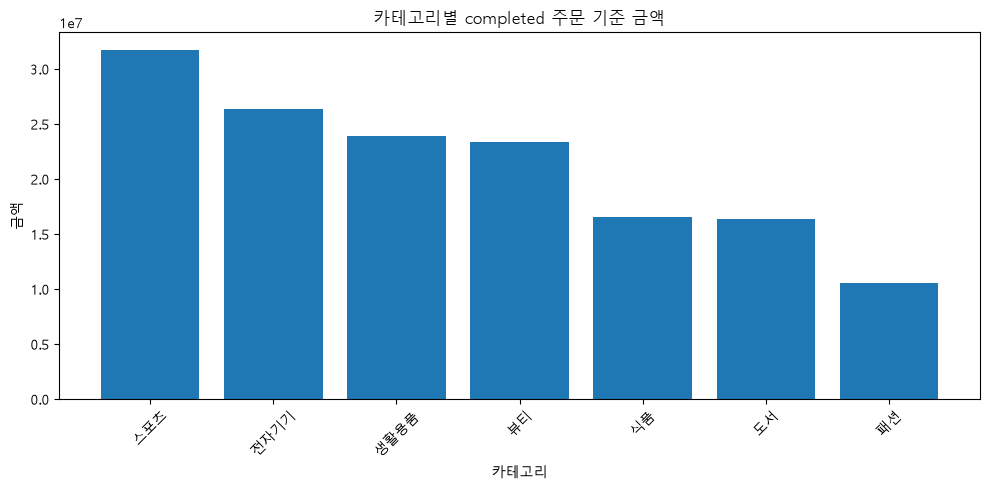

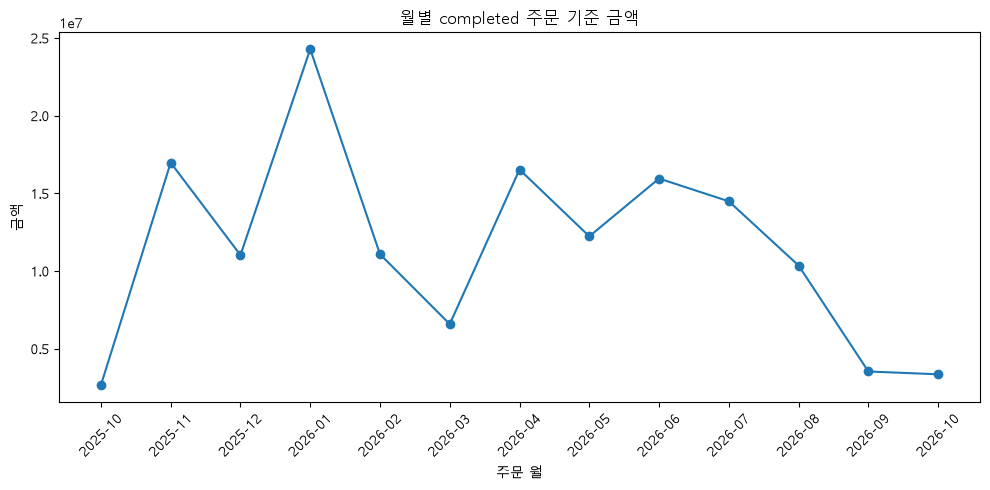

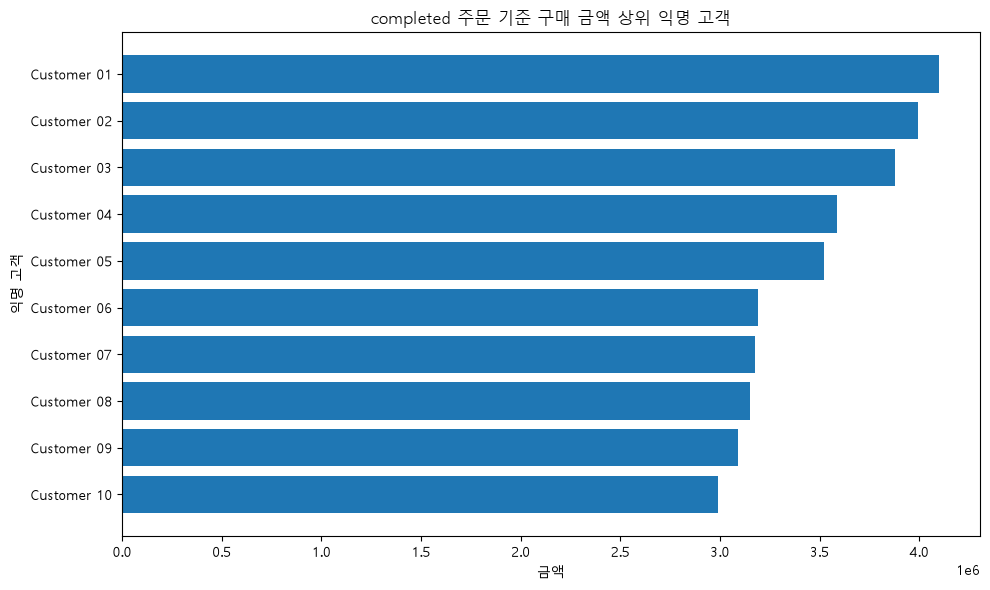

ch08_category_sales.png True 28333
ch08_monthly_sales.png True 75447
ch08_top_customers.png True 47302


In [15]:
saved_figures = create_project_figures(
    analysis_tables,
    FIGURE_DIR,
    show=True,
)

for path in saved_figures:
    print(path.name, path.exists(), path.stat().st_size)


In [16]:
figure_totals = {
    "category_sales": analysis_tables["category_sales"]["total_sales"].sum(),
    "monthly_sales": analysis_tables["monthly_sales"]["total_sales"].sum(),
    "customer_sales_top10": (
        analysis_tables["customer_sales_public"]
        ["total_sales"]
        .sum()
    ),
}

category_total = figure_totals["category_sales"]
monthly_total = figure_totals["monthly_sales"]
customer_sales_total = figure_totals["customer_sales_top10"]
print(f"카테고리별 합계: {category_total:}원")
print(f"월별 합계: {monthly_total:}원")
print(f"고객별 합계: {customer_sales_total:}원")

카테고리별 합계: 148990000원
월별 합계: 148990000원
고객별 합계: 148990000원


## 6. 대표 시각화
![대표 그래프 1](images/graph_01.png)
![대표 그래프 2](images/graph_02.png)

### 그래프 선택 이유
첫 번째 카테고리별 매출 그래프는 막대그래프를 선정하였다. 막대그래프로 나타낸 까닭은 카테고리별 비교가 필요하고, 각 카테고리들이 유관성을 갖지 않으므로 각각의 값을 막대로 나타내고 시각적으로 차이가 보이게하는 것이 효과적일 것이라고 판단했다.

두 번째 월별 completed 주문 기준 금액은 꺾은 선 그래프로 시간순에 따라 표현하였다. 그 까닭은 '월별'이므로 시간의 흐름을 가지고 있어 이를 반영하고자 하였고, 각 시기가 연속적이므로 꺾은 선 그래프를 통해 연결하여 제시하였다.

### 그래프와 원본 집계값 일치 여부
일치한다. 앞선 원본 집계값이 148990000.0이었으므로, 그래프 데이터의 전체 합산값(카테고리별, 월별, 고객별)을 확인한 결과 일치하였다.

### 그래프에서 직접 관찰한 사실
스포츠, 전자기기, 생활용품, 뷰티, 식품, 도서, 패션 순으로 주문 완료 금액이 크다. 또한, 다른 월대비 2026년 1월의 주문 완료금액이 상대적으로 높은 것을 볼 수 있었다. 2025년 10월, 2026년 9월과 10월은 다른 월대비 상대적으로 주문 완료 금액이 낮았다.

### 그래프만으로 말할 수 없는 것
현재 표기상 각 주문 완료금액을 나타내지 않았으므로, 얼마나 많은지를 정량적으로 그래프를 보고 말할 수 없다. 또한 현재의 데이터를 가지고 주문 완료 금액 차이의 원인을 특정할 수 없다.


## 7. 개인정보 검증
- 공개 고객 CSV 컬럼: ['customer_label', 'city', 'order_count', 'total_sales', 'avg_order_value']
- 원본 `customer_id` 포함 여부: X
- 이름/이메일/전화번호/주소 포함 여부: X
- 익명 라벨 방식: customer_label(넘버링)
- PASS/FAIL: PASS

### 나의 판단
customer_id를 비롯하여 고객의 민감한 정보가 산출 CSV에 포함되지 않았다. 따라서 개인정보를 보호했다고 말할 수 있으며, 이러한 작업은 산출물을 공유함에 있어 필수적이다.

## 14. Markdown 보고서 생성

보고서에는 계산 기준, PK/FK·병합, `line_total`, total consistency, 개인정보, 최종 Validation을 함께 남깁니다.


In [17]:
report_text = build_midterm_report(
    dataset_summary,
    preprocessing_comparison,
    key_duplicate_checks,
    relationship_checks,
    analysis_tables,
    interpretation_notes,
)

report_path = REPORT_DIR / "ch08_midterm_report.md"
report_path.write_text(report_text, encoding="utf-8")

print("보고서 저장:", report_path)
print(report_text[:1800])


보고서 저장: C:\dev\llm-data-analysis-study\reports\ch08_midterm_report.md
# Chapter 8 중간 프로젝트 보고서

## 1. 분석 목적

온라인 쇼핑몰 데이터를 사용해 completed 주문 기준 금액과 고객 구매 패턴을 분석했습니다.

## 2. 분석 기준

- 금액성 분석은 `order_status == "completed"`인 주문만 포함했습니다.
- `line_total = quantity × unit_price` 관계를 검증했습니다.
- 취소·환불 등 non-completed 주문을 포함한 금액은 전체 주문 상세 금액으로 구분했습니다.
- 공개 고객 결과에서는 이름·연락처·원본 고객 ID를 제외하고 순위 기반 익명 라벨을 사용했습니다.
- 병합은 관계 검증, `validate`, 행 수, 미매칭을 확인했습니다.
- 같은 completed 범위의 카테고리·월·고객 총합을 source total과 대조했습니다.

## 3. 데이터 개요

```text
    dataset  rows  columns  missing_values  duplicated_rows
  customers   150        6               0                0
   products   100        4               0                0
     orders   300        5               0                0
order_items   764        5               0                0
```

## 4. 전처리 전후 비교

```text
    dataset  rows_raw  columns_raw  rows_processed  columns_processed
  customers       150            6             150                  6
order_items  

## 8. 최종 Validation
`reports/ch08_project_validation.csv`의 결과를 요약합니다.

| 검증 항목 | 결과 | 내가 확인한 근거 |
| --- | --- | --- |
| pk_integrity | PASS | 중복, 결측 X |
| fk_integrity | PASS | 부모 테이블에 없는 참조 ID가 존재하지 않음. |
| merge_checks_pass | PASS | 병합 전후 행수 변화와 미매칭 확인, 날짜변환 실패가 존재하는지 확인 |
| line_total_consistency | PASS | line_total 계산이 올바르게 진행되었는지-각 행에서 unit_price, quantity가 있는지, 곱셈계산이 되었는지 확인 |
| completed_total_consistency | PASS | 각 분석에서의 완료 주문액 합계가 원본 집계합과 일치 |
| category_sales_ratio_pct_sum | PASS | 퍼센트 총합이 100 |
| completed_rows_with_invalid_order_date | PASS | 날짜변환 실패행 X |
| public_customer_columns_safe | PASS | customer_id를 비롯한 민감정보 미포함 |

### FAIL이 있었다면 수정 내용

## 15. 전체 파이프라인 재실행

단계별 셀을 확인한 뒤에는 `run_midterm_project()`로 원본부터 보고서까지 다시 실행합니다. Notebook의 이전 메모리 상태에 의존하지 않는지 확인하는 단계입니다.


In [18]:
project_result = run_midterm_project(
    raw_dir=RAW_DIR,
    processed_dir=PROCESSED_DIR,
    report_dir=REPORT_DIR,
    figure_dir=FIGURE_DIR,
    show_figures=False,
)

display(project_result["project_validation"])
project_result["report_path"]


,check,value,expected,status
0,pk_integrity,all PASS,all PASS,PASS
1,fk_integrity,0,0,PASS
2,merge_checks_pass,all PASS,all PASS,PASS
3,line_total_consistency,0,0,PASS
4,completed_total_consistency,all match,all match,PASS
5,category_sales_ratio_pct_sum,100.0,100.0,PASS
6,completed_rows_with_invalid_order_date,0,0,PASS
7,public_customer_columns_safe,no forbidden columns,no forbidden columns,PASS


WindowsPath('C:/dev/llm-data-analysis-study/reports/ch08_midterm_report.md')

## 16. 최종 산출물 검증

필수 CSV·PNG·Markdown이 존재하고 비어 있지 않은지 확인합니다.


In [19]:
expected_outputs = [
    REPORT_DIR / "ch08_midterm_report.md",
    REPORT_DIR / "ch08_dataset_summary.csv",
    REPORT_DIR / "ch08_preprocessing_comparison.csv",
    REPORT_DIR / "ch08_key_duplicate_checks.csv",
    REPORT_DIR / "ch08_relationship_checks.csv",
    REPORT_DIR / "ch08_merge_checks.csv",
    REPORT_DIR / "ch08_line_total_check.csv",
    REPORT_DIR / "ch08_date_checks.csv",
    REPORT_DIR / "ch08_amount_scope_summary.csv",
    REPORT_DIR / "ch08_total_consistency_check.csv",
    REPORT_DIR / "ch08_project_validation.csv",
    REPORT_DIR / "ch08_category_sales.csv",
    REPORT_DIR / "ch08_monthly_sales.csv",
    REPORT_DIR / "ch08_customer_sales.csv",
    REPORT_DIR / "ch08_order_status_summary.csv",
    REPORT_DIR / "ch08_interpretation_notes.csv",
    FIGURE_DIR / "ch08_category_sales.png",
    FIGURE_DIR / "ch08_monthly_sales.png",
    FIGURE_DIR / "ch08_top_customers.png",
]

all_outputs_valid = True
for path in expected_outputs:
    valid = path.exists() and path.stat().st_size > 0
    all_outputs_valid &= valid
    print(path.name, "OK" if valid else "MISSING OR EMPTY")

assert all_outputs_valid
print("전체 산출물 검증: PASS")


ch08_midterm_report.md OK
ch08_dataset_summary.csv OK
ch08_preprocessing_comparison.csv OK
ch08_key_duplicate_checks.csv OK
ch08_relationship_checks.csv OK
ch08_merge_checks.csv OK
ch08_line_total_check.csv OK
ch08_date_checks.csv OK
ch08_amount_scope_summary.csv OK
ch08_total_consistency_check.csv OK
ch08_project_validation.csv OK
ch08_category_sales.csv OK
ch08_monthly_sales.csv OK
ch08_customer_sales.csv OK
ch08_order_status_summary.csv OK
ch08_interpretation_notes.csv OK
ch08_category_sales.png OK
ch08_monthly_sales.png OK
ch08_top_customers.png OK
전체 산출물 검증: PASS


## 17. LLM 검토 프롬프트 예시

원본 고객 행이나 직접 식별정보 대신 비식별 검증 Evidence를 제공합니다.

```text
온라인 쇼핑몰 중간 프로젝트 결과를 검토해 주세요.

계산 기준:
- line_total = quantity × unit_price
- 금액성 분석은 order_status == completed만 사용

검증 결과:
- PK 결측/중복: 0
- FK 미매칭: 0
- merge checks: PASS
- category/month/customer totals: source total과 일치
- completed 주문 날짜 오류: 0
- 공개 고객 CSV에 원본 customer_id 없음

다음을 검토해 주세요.
1. 아직 확인하지 않은 분석 위험
2. 과도한 해석이 될 수 있는 표현
3. 보고서에 반드시 적어야 할 계산 기준
4. 추가로 필요한 검증
5. 데이터에 없는 원인은 추정하지 않기
```

LLM은 검토 범위를 넓히는 도구이지 프로젝트의 최종 승인자가 아닙니다.


## 9. LLM 활용 기록
- 사용 여부: X 이하 생략
- 사용 목적: 
- Safe Context:
- Prompt 요약:
- 제안 요약:
- 반영/수정/보류:
- 사람이 검증한 근거:

## 10. 프로젝트 재현 확인
- `python scripts/run_midterm_project.py` 실행 여부: O
- 재실행 결과: 성공
- Notebook과 핵심 수치 일치 여부: 일치
- 생성된 핵심 Evidence 파일 확인 여부: O

![재실행 결과](images/step06_reproduce.png)

### 나의 해석과 판단
프로젝트의 run 결과가 나와있는 화면 자체를 공유하는 것이 아니라 산출물이나 프로젝트 코드 자체를 공유하기 때문에 재현성 있도록 프로젝트가 설계되어야 신뢰도가 높아진다. 또한, 재현 가능해야 각자 필요한 범주에서 프로젝트를 수정할 수 있다.

## 18. 실습 과제

1. 핵심 EDA 결과 3개를 선택하고 각각 근거와 한계를 작성합니다.
2. 대표 그래프 2~4개를 선택하고 원본 집계값과 일치하는지 확인합니다.
3. `ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인합니다.
4. 공개 고객 CSV에 개인정보가 없는지 다시 확인합니다.
5. LLM을 사용했다면 목적·Prompt 요약·제안·반영 여부·사람의 검증 근거를 기록합니다.
6. `python scripts/run_midterm_project.py`로 전체 프로젝트를 다시 실행하고 Notebook의 핵심 수치와 비교합니다.


In [48]:
# 실습 과제 코드를 아래에 작성하세요.
# 기본적인 흐름인 이 노트북안에 재현되어 있으므로, 초기에 세웠던 질문을 해결하는 코드를 하나 작성했습니다. 
# 나머지 2개에 대한 결과는 파일 중간에 있는 markdown셀로 보충합니다.
# 대표 그래프도 마찬가지입니다.
# 4-6번도 상단에서 답하였으므로 생략합니다.

# 계절구분은 입춘, 입하, 입추, 입동 날짜를 기준으로 하였다.
season_months = {
    "봄(2~4월)": ["2026-02", "2026-03", "2026-04"],
    "여름(5~7월)": ["2026-05", "2026-06", "2026-07"],
    "가을(8~10월)": ["2026-08", "2026-09", "2026-10", "2025-10"],
    "겨울(11~1월)": ["2025-11", "2025-12", "2026-01"],
}

monthly_sales = monthly_sales.copy()

# order_month가 "2025-10" 형식이라고 가정
monthly_sales["month"] = (
    monthly_sales["order_month"]
    .astype(str)
)

seasonal_sales = pd.DataFrame([
    {
        "season": season,
        "total_sales": monthly_sales.loc[
            monthly_sales["month"].isin(months), "total_sales"
        ].sum(),
    }
    for season, months in season_months.items()
])
seasonal_sales.head()

,season,total_sales
0,봄(2~4월),34186000
1,여름(5~7월),42659000
2,가을(8~10월),19876000
3,겨울(11~1월),52269000


In [42]:
seasonal_sales["total_sales"].sum()

np.int64(148990000)

In [43]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import pandas as pd

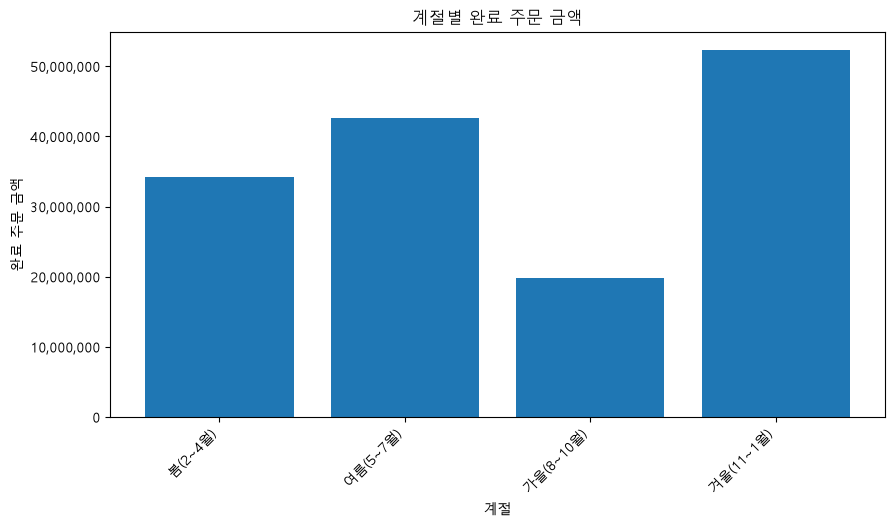

In [49]:
seasons = ["봄(2~4월)", "여름(5~7월)", "가을(8~10월)", "겨울(11~1월)"]
seasonal_sales["season"] = pd.Categorical(seasonal_sales["season"], categories=seasons, ordered=True)
seasonal_sales= seasonal_sales.sort_values("season")

fig, ax= plt.subplots(figsize=(10,5))
ax.bar(seasonal_sales["season"], seasonal_sales["total_sales"])
ax.set_title("계절별 완료 주문 금액")
ax.set_xlabel("계절")
ax.set_ylabel("완료 주문 금액")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, position: f"{value:,.0f}"))
ax.tick_params(axis="x", rotation=45)
for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

#결과 관찰 및 집계 확인

계절별 집계결과 봄에 34186000, 여름에 42659000, 가을에 19876000, 겨울에 52269000으로 집계되었다. 또한, total_sales의 합을 검증한 결과 completed 원본 집계합과 일치하였다.

#해석

분석 결과를 관찰한 결과, 겨울에 가장 많은 주문 완료금액, 그 다음이 여름이었다. 이는 날씨가 비교적 극단적인 계절에 판매액이 높은 것으로 해석할 수 있다. 이를 뒷받침하기 위해 월별 집계결과와 월별 평균 기온을 함께볼 필요가 있다. 업무적으로는 계절별 판매량을 통해 마케팅 계획을 수립할 수 있다.

#그래프

시각화 그래프로 나타낸 결과, 겨울의 주문완료금액이 크고 가을이 낮은 것이 눈에 들어왔다.
그러나 가을의 경우, 2025-10과 2026-10을 포함한다. 해당 월은 데이터의 범위상 시작일이 2025년 10월 14일, 종료일이 2026년 10월 13일이므로 데이터가 한달의 양을 포함한다고 볼 수 있다. 따라서 그래프에 표현된 대로 해석해도 무리가 없다고 판단하였다.


3번

`ch08_total_consistency_check.csv`와 `ch08_project_validation.csv`를 확인한 결과 두 파일에서 status값이 모두 PASS였다.


## 정리

이번 장에서는 원본 데이터 확인, 전처리, PK/FK, 병합, `line_total`, completed 범위, total consistency, 날짜, 개인정보, 시각화, 보고서, 최종 Validation을 하나의 프로젝트로 연결했습니다.

기억할 핵심은 다음과 같습니다.

```text
실행 성공 ≠ 검증 완료
같은 의미의 숫자는 서로 다른 집계에서도 같아야 한다
공개 결과에는 불필요한 개인정보를 남기지 않는다
프로젝트는 원본부터 다시 실행할 수 있어야 한다
```


## 11. 최종 프로젝트 요약
### 핵심 인사이트 3개
1. 데이터 분석에서 전처리부터 정확히 이루어져야 나중에 귀찮지 않다.
2. 각 단계단계마다 진행상태와 결과를 확인하고 문제가 있으면 바로잡고 넘어가야한다.
3. 프로젝트가 재현가능해야하고, 산출물을 CSV나 이미지 파일로 저장하는 것이 중요하다.

### 가장 중요한 업무·분석적 의미
이번에 종합적 분석을 하면서 데이터 분석 각 단계에서 문제가 있는지 확인하고 바로 잡는 것이 필요하다는 것을 뼈저리게 느꼈다. 미룰수록 더 꼬이고, 분석 시간을 지연시키기 때문에 효율이 떨어진다. 따라서 바로바로 수정해야한다.

### 현재 분석의 한계
주어진 데이터에 의거하기 때문에 데이터 외적인 회사의 상황을 알 수 없다. 따라서 금전적인 내용 이외의 운영에 대한 정보가 있으면 좋다.

### 다음 분석 제안
1. 
2.
3.

## 최종 체크
- [O] 질문과 지표가 연결됩니다.
- [O] 원본 데이터에서 다시 시작했습니다.
- [O] PK/FK·병합 검증 근거가 있습니다.
- [O] `line_total` 계산 관계를 확인했습니다.
- [O] 금액성 분석은 completed 범위를 사용했습니다.
- [O] category/month/customer 총합이 source total과 일치합니다.
- [O] 날짜 오류를 확인했습니다.
- [O] 공개 고객 결과에서 원본 ID와 직접 식별정보를 제거했습니다.
- [O] 대표 그래프와 원본 집계값을 비교했습니다.
- [O] 원인 과대 해석이 없습니다.
- [O] 최종 Validation이 모두 PASS입니다.
- [O] 전체 프로젝트를 재실행했습니다.
- [O] 한계와 다음 분석을 작성했습니다.
- [O] 최종 Notebook URL을 제출합니다.

